# Events, Tracks And Hits

**Version**: 1

**Last modified**: 2026-10-12

**Compatible with opengate-gate-tree version:** 0.7.0

**Author**: Mateusz Jakub Bała

## About

A row of the "Hits" tree is one hit, but the questions an analysis of a
`PositroniumSource` asks are about events and the gammas in them: how many
gammas an event left in the detector, which of them is the prompt one, whether
the first interaction of a gamma was a Compton scattering. Answering them on
rows means grouping the rows again for every question.

`EventTrackHit` groups them once - into events, the tracks recorded in each,
and the hits every track left - and reads everything else from the columns only
when it is asked for. This notebook builds one, looks at a single event the way
it is thought of, reads the whole file as tables, selects events, tracks and
hits, writes the result and reads it back, and finally groups hits that two
detectors recorded in two trees.

## What will you learn from this notebook

- build the representation from a file, and read how many tracks every event
  has and how many hits every track has
- look at one event, its tracks and their hits as objects
- read any field as a table with a row per event, per track or per hit, and go
  from a hit back to the row of the file it came from
- select by the kind of gamma, the process, a count or a position - and see why
  the order of two selections changes the question
- ask about one hit of every track at once, such as "the first hit is a
  Compton scattering"
- write the representation as a `.eth` file and read it back
- group hits that one tree per sensitive detector split between two trees

## Tutorial

Every step below is a line of text, the code that does what the line says, and
a word about the answer where the answer needs one.

In [1]:
from tools import environment, paths, plotting

plotting.use_tutorial_style()
print(environment.describe())

opengate-gate-tree: 0.6.0
python: 3.14.5
run on: 2026-10-12


The header of this notebook states the version it was written for; the line
above states the version it just ran against. If they differ, the notebook may
still be right — but nobody has checked it against what is installed.

Two small GATE outputs carried in the repository, both described in
[`../data/README.md`](../data/README.md): 500 hits of a scene with a
`PositroniumSource` configured with every channel at once, and the hits of two
sensitive detectors written as one tree each. The notebook writes one file, so
it has a directory of its own.

In [2]:
positronium_input = paths.input_example("positronium-source-all-variants.root")
detectors_input = paths.input_example("hits-one-tree-per-detector.root")

output = paths.output_dir("tutorial-18-events-tracks-and-hits")
output.relative_to(paths.TUTORIALS_DIR)

PosixPath('notebooks/.tmp/tutorial-18-events-tracks-and-hits')

In [3]:
import numpy as np
import pandas as pd

from opengate_gate_tree import (
    DecayType,
    EventTrackHit,
    EventTrackHitField,
    GammaType,
    GateTree,
    OutputFileFormat,
    Process,
    SourceType,
    build_event_track_hit_file_path,
    position_in_track,
    read_event_track_hit,
    read_hits_trees,
    read_tree,
    reduce_hits_to_tracks,
    write_event_track_hit,
)

Field = EventTrackHitField
frame = read_tree(positronium_input, GateTree.HITS).to_dataframe()

### From Rows To Events

Building the representation reads four columns - `runID`, `eventID`, `trackID`
and `time` - groups the rows, and keeps a reference to the frame rather than a
copy of it:

In [4]:
representation = EventTrackHit(frame)
representation

EventTrackHit(events=115, tracks=311, hits=500)

The 500 rows are 115 events of 311 tracks. What the grouping says is known
from the start: how many tracks every event has, and how many hits every track
has.

In [5]:
tracks_per_event = pd.Series(representation.track_counts()).value_counts().sort_index()
hits_per_track = pd.Series(representation.hit_counts()).value_counts().sort_index()
tracks_per_event.to_dict(), hits_per_track.to_dict()

({2: 53, 3: 43, 4: 19}, {1: 181, 2: 86, 3: 31, 4: 11, 5: 2})

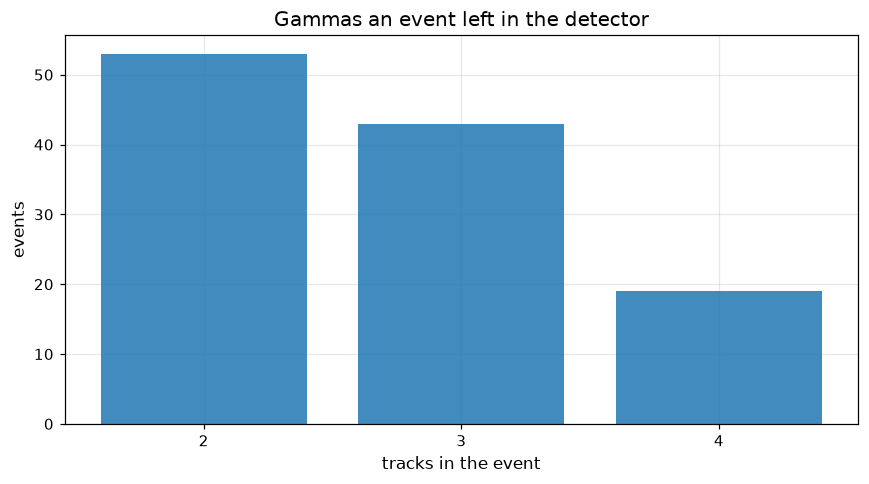

In [6]:
plotting.plot_bar(
    tracks_per_event.index,
    tracks_per_event.to_numpy(),
    xtitle="tracks in the event",
    ytitle="events",
    title="Gammas an event left in the detector",
);

Which source model emitted the event tells why: a para-positronium decay gives
two annihilation gammas, an ortho-positronium decay three, and a decay with
de-excitation adds a prompt gamma to either. `sourceType` describes the whole
event, so it is read once per event:

In [7]:
events = representation.events_frame([Field.SOURCE_TYPE, Field.TRACK_COUNT])
events["source"] = events["sourceType"].map(lambda value: SourceType(value).name)
pd.crosstab(events["source"], events["trackCount"])

trackCount,2,3,4
source,,,
DIRECT_ANNIHILATION,14,0,0
NOT_DEFINED,18,0,0
ORTHO_POSITRONIUM,0,32,19
PARA_POSITRONIUM,21,11,0


Every ortho-positronium event left at least three gammas, and the
para-positronium events with three are the ones with a prompt gamma. Two-gamma
events also come from direct annihilation and from the back-to-back source
(`NOT_DEFINED`).

### One Event, As Objects

The events are a sequence of objects, each holding its tracks, each holding its
hits. They are made only when asked for, and read their values from the frame
at that moment. Event 4 is an ortho-positronium decay with a prompt gamma:

In [8]:
event = representation.events[4]
event, event.source_type

(Event(runID=0, eventID=4, tracks=4), <SourceType.ORTHO_POSITRONIUM: 3>)

In [9]:
[(track.track_id, track.gamma_type.name, track.hit_count) for track in event.tracks]

[(1, 'PROMPT', 2),
 (2, 'ANNIHILATION', 1),
 (3, 'ANNIHILATION', 1),
 (4, 'ANNIHILATION', 1)]

The tracks come in the order of their identifiers, and track 1 is the prompt
gamma - the first particle the source emitted. That is not the order GATE wrote
them in; the rows of this event in the file run from the last track to the
first:

In [10]:
frame.gate.by_event(event.run_id, event.event_id)["trackID"].tolist()

[4, 3, 2, 1, 1]

Within a track, hits come in the order of their time, numbered from 1. Every
hit knows the row of the file it was read from:

In [11]:
prompt = event.tracks[0]
[(hit.number, hit.process_name, round(hit.edep * 1000, 1), hit.row) for hit in prompt.hits]

[(1, 'Compton', 712.2, 19), (2, 'PhotoElectric', 587.8, 20)]

The prompt gamma scattered once and was absorbed in its second interaction. Its
two deposits add up to 1300 keV - the whole energy of a gamma no annihilation,
at 511 keV, could have deposited.

### The Whole File, As Tables

Objects are for looking at one event. A question about every event is read as a
table instead - one row per event, per track or per hit, with the fields asked
for:

In [12]:
representation.tracks_frame(
    [Field.EVENT_ID, Field.TRACK_ID, Field.GAMMA_TYPE, Field.HIT_COUNT]
).head(8)

,eventIndex,eventID,trackID,gammaType,hitCount
trackIndex,,,,,
0,0,0,1,2,2
1,0,0,2,2,2
2,1,1,1,2,1
3,1,1,2,2,4
4,2,2,1,2,1
5,2,2,2,2,2
6,2,2,3,2,1
7,3,3,1,0,2


`eventIndex` is the position of the event of every track, from 0; `trackNumber`
is the position of the track in its event, from 1. The hits table adds where
every hit stands, and is labelled with the rows of the frame:

In [13]:
hits = representation.hits_frame(
    [Field.EDEP, Field.PROCESS_NAME, Field.POS_X, Field.POS_Y, Field.POS_Z]
)
hits.head()

,eventIndex,trackIndex,trackNumber,hitNumber,edep,processName,posX,posY,posZ
2,0,0,1,1,0.220403,Compton,186.769531,-2.133321,79.422951
3,0,0,1,2,0.290596,PhotoElectric,186.650757,-2.092664,80.146744
0,0,1,2,1,0.094538,Compton,-184.148819,2.103387,-78.308502
1,0,1,2,2,0.416461,PhotoElectric,-184.547928,2.548918,-78.674561
8,1,2,1,1,0.510999,PhotoElectric,-177.181198,-81.951614,-93.412117


The columns keep the names GATE wrote, so the `gate` namespace works on the
table as on the frame - here, how far from the centre every hit happened:

In [14]:
hits.gate.position().norm().describe()[["min", "max"]]

min    200.002435
max    263.507327
Name: norm, dtype: float64

And the labels lead back to the frame, row for row:

In [15]:
frame.loc[hits.index[:3], ["eventID", "trackID", "edep", "processName"]]

,eventID,trackID,edep,processName
2,0,1,0.220403,Compton
3,0,1,0.290596,PhotoElectric
0,0,2,0.094538,Compton


### Selecting

Every question comes in two forms: `is_*` answers with a mask of the level it
asks about, and `with_*`, `nth_*` or `select_*` with a new representation of
what was kept. A selection never changes the representation it was made on.

The first hit of every track, and the last:

In [16]:
first = representation.first_hits().hits_frame([Field.PROCESS_NAME])
last = representation.last_hits().hits_frame([Field.PROCESS_NAME])
first["processName"].value_counts().to_dict(), last["processName"].value_counts().to_dict()

({'PhotoElectric': 180, 'Compton': 131}, {'PhotoElectric': 310, 'Compton': 1})

Almost every gamma ends in a photoelectric absorption; one scattered and left
the detector.

A selection of hits leaves out the tracks it empties, and a selection of tracks
the events it empties - unless asked to keep them:

In [17]:
compton = representation.with_process(Process.COMPTON)
compton_kept = representation.with_process(Process.COMPTON, keep_empty=True)
compton, compton_kept

(EventTrackHit(events=92, tracks=131, hits=190),
 EventTrackHit(events=115, tracks=311, hits=190))

Of 311 tracks, 131 scattered at least once. With `keep_empty=True` the other
180 stay, without hits, but still the tracks they were: a track keeps its
identifier and its kind of gamma whatever hits it has left.

#### The order of selections is part of the question

A count asked for after a selection counts what the selection kept. These are
two questions:

In [18]:
annihilation = GammaType.ANNIHILATION
two_annihilation_gammas = representation.with_gamma_type(annihilation).with_track_count(2)
two_gammas_both_annihilation = representation.with_track_count(2).with_gamma_type(annihilation)
two_annihilation_gammas.event_count, two_gammas_both_annihilation.event_count

(46, 35)

The first counts the events with two annihilation gammas, whatever else they
left: that includes the eleven para-positronium decays with a prompt gamma
beside them. The second takes the events of exactly two gammas first - which
leaves out those eleven - and then keeps their annihilation gammas, which
removes the eighteen back-to-back events, whose gammas are not annihilation
gammas of a positronium source. 46 and 35: two different questions, each
answered right.

#### A condition on one hit of every track

"The first hit is a Compton scattering" is a condition on one hit that decides
about its whole track. It is a mask of hits - the hits at position 1 that are
Compton scatterings - reduced to the tracks:

In [19]:
every_hit = np.ones(representation.hit_count, dtype=bool)
at_first = position_in_track(representation.index, every_hit) == 1
starts_with_compton = reduce_hits_to_tracks(
    representation.index, at_first & representation.is_process(Process.COMPTON), "any"
)
int(starts_with_compton.sum())

131

Put together, this asks for the events in which both annihilation gammas of a
para-positronium decay scattered once and were then absorbed:

In [20]:
pairs = (
    representation.with_source_type(SourceType.PARA_POSITRONIUM)
    .with_decay_type(DecayType.STANDARD)
    .with_track_count(2)
    .with_hit_count(2)
)
for position, process in ((1, Process.COMPTON), (2, Process.PHOTOELECTRIC)):
    every_hit = np.ones(pairs.hit_count, dtype=bool)
    at = position_in_track(pairs.index, every_hit) == position
    passes = reduce_hits_to_tracks(pairs.index, at & pairs.is_process(process), "any")
    pairs = pairs.select_tracks(passes)
pairs = pairs.with_track_count(2)

pairs.hits_frame([Field.EVENT_ID, Field.TRACK_ID, Field.PROCESS_NAME, Field.EDEP])

,eventIndex,trackIndex,trackNumber,hitNumber,eventID,trackID,processName,edep
2,0,0,1,1,0,1,Compton,0.220403
3,0,0,1,2,0,1,PhotoElectric,0.290596
0,0,1,2,1,0,2,Compton,0.094538
1,0,1,2,2,0,2,PhotoElectric,0.416461


One event of this small file answers it: both gammas scattered and were
absorbed, and the deposits of each add up to 511 keV. The last
`with_track_count(2)` is needed: without it, an event in which only one of the
two gammas passed would stay. This file holds only a few para-positronium
decays; the same question on a whole simulation is what the analysis of version
0.8.0 is built for.

#### A mask built on the frame

A mask built on the frame the representation came from selects the hits of its
rows - it is read by its labels, not by its positions, which differ, since
GATE writes the tracks of an event from the last one:

In [21]:
large = frame["edep"] > 0.4
representation.select_hits(large).hit_count, int(large.sum())

(149, 149)

### Writing And Reading Back

The representation is written as a flat tree of its hits, in its own order,
with five columns saying where every hit stands. Here the pairs found above:

In [22]:
path = build_event_track_hit_file_path(output, "pps-pairs", OutputFileFormat.ROOT)
write_event_track_hit(pairs, path, OutputFileFormat.ROOT)
path.relative_to(paths.TUTORIALS_DIR)

PosixPath('notebooks/.tmp/tutorial-18-events-tracks-and-hits/pps-pairs.eth.root')

Any reader of ROOT files sees the grouping without this package:

In [23]:
written = read_tree(path, GateTree.HITS, validate=False).to_dataframe()
written[["eventID", "trackID", "eventIndex", "trackNumber", "hitNumber", "trackCount", "hitCount"]]

,eventID,trackID,eventIndex,trackNumber,hitNumber,trackCount,hitCount
0,0,1,0,1,1,2,2
1,0,1,0,1,2,2,2
2,0,2,0,2,1,2,2
3,0,2,0,2,2,2,2


Reading it back with the package groups the rows again and checks them against
those columns, so a file whose rows were reordered or whose columns were
changed is refused:

In [24]:
again = read_event_track_hit(path)
same_deposits = np.array_equal(again.values(Field.EDEP), pairs.values(Field.EDEP))
again, same_deposits

(EventTrackHit(events=1, tracks=2, hits=4), True)

### Hits Of Two Detectors

A simulation that writes one tree per sensitive detector records a gamma that
crosses both in both trees. Read as one dataset, the rows of such a track are
no longer neighbours, and the representation sorts every row instead of only
the blocks of rows a track occupies - the grouping is the same either way:

In [25]:
detectors = EventTrackHit(read_hits_trees(detectors_input))
detectors

EventTrackHit(events=305, tracks=537, hits=1000)

In [26]:
detector_hits = detectors.hits_frame(["sourceTreeName", Field.TRACK_ID, Field.TIME])
trees_per_track = detector_hits.groupby("trackIndex")["sourceTreeName"].nunique()
int((trees_per_track > 1).sum())

65

65 tracks have hits in both detectors. One of them, its hits in the order of
their time:

In [27]:
crossing = int(trees_per_track[trees_per_track > 1].index[0])
detector_hits[detector_hits["trackIndex"] == crossing]

,eventIndex,trackIndex,trackNumber,hitNumber,sourceTreeName,trackID,time
18,10,19,2,1,Hits_DET_INNER,2,0.000072
509,10,19,2,2,Hits_DET_OUTER,2,0.000072


## Summary

`EventTrackHit` groups the rows of a "Hits" tree once into events, tracks and
hits, knows from the start how many of each there are, and reads every other
value only when asked - as objects for one event, as tables for all of them.
Selections keep what they are asked to and count what they kept, so their order
is part of the question; the result is written as a flat `.eth` file that any
reader can follow and this package can check.

## Bibliography

- [Events, Tracks And Hits](https://opengate-gate-tree.readthedocs.io/en/latest/guide/event-track-hit.html)
  — the representation, its order, fields, selectors and file
- [Event Identifiers](https://opengate-gate-tree.readthedocs.io/en/latest/guide/events.html)
  — why an event is the pair `(runID, eventID)`
- [PositroniumSource Data](https://opengate-gate-tree.readthedocs.io/en/latest/guide/positronium.html)
  — what `sourceType`, `decayType` and `gammaType` mean
- [Merging Trees](https://opengate-gate-tree.readthedocs.io/en/latest/guide/merging.html)
  — reading one tree per sensitive detector as one dataset

## Changelog

- v1: written.